# Python DS Assignment 2: Data Visualization (NYC Taxi Trips)

**Goal:** clean the seaborn `taxis` dataset and explore fare, distance and customer behaviour with Pandas/Matplotlib and Seaborn.

**Contents**
1. Load the data
2. Handle missing values
3. Matplotlib / Pandas plots: line, bar, pie, histogram, box
4. Seaborn plots: count, scatter, heatmap, pair, violin
5. Key takeaways

## 1. Load the dataset

In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")
print("Shape:", df.shape)
df.head()

Shape: (6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


## 2. Handling missing values

### 2.1 Check for missing values

In [3]:
missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0]

,missing,percent
payment,44,0.68
pickup_zone,26,0.40
dropoff_zone,45,0.70
pickup_borough,26,0.40
dropoff_borough,45,0.70


### 2.2 Strategy

All missing values are in **categorical** columns, so mean/median imputation does not apply. The decision per column:

| Column | Missing | Decision | Why |
|---|---|---|---|
| `payment` | 44 | **Impute with mode** | One of only two categories (credit card / cash); the mode is a reasonable fill and the rest of the row (fare, distance, etc.) is still valid. |
| `dropoff_zone`, `dropoff_borough` | 45 | **Impute with mode** | Not used as a key axis in this analysis; the rest of the trip is valid, so the row is kept. |
| `pickup_zone`, `pickup_borough` | 26 | **Drop rows** | These are critical: the bar, box, count, scatter colouring and pair plot are all grouped by pickup location. Filling a location with the most common value would silently distort every per-borough result. |

The numeric columns have no missing values, so no mean/median imputation is needed.

In [4]:
df_clean = df.copy()

# 1) Critical location columns: drop rows (cannot be reasonably imputed)
before = len(df_clean)
df_clean = df_clean.dropna(subset=["pickup_zone", "pickup_borough"])
print(f"Dropped {before - len(df_clean)} rows with missing pickup location")

# 2) Remaining categorical columns: impute with the mode
for col in ["payment", "dropoff_zone", "dropoff_borough"]:
    mode_val = df_clean[col].mode()[0]
    n = df_clean[col].isnull().sum()
    df_clean[col] = df_clean[col].fillna(mode_val)
    print(f"{col}: filled {n} missing values with mode = '{mode_val}'")

df_clean = df_clean.reset_index(drop=True)
print("\nMissing values after cleaning:", int(df_clean.isnull().sum().sum()))
print("Final shape:", df_clean.shape)

Dropped 26 rows with missing pickup location
payment: filled 43 missing values with mode = 'credit card'
dropoff_zone: filled 24 missing values with mode = 'Upper East Side North'
dropoff_borough: filled 24 missing values with mode = 'Manhattan'

Missing values after cleaning: 0
Final shape: (6407, 14)


## 3. Visualizations using Matplotlib / Pandas plot

### 3.1 Line chart: fare over time

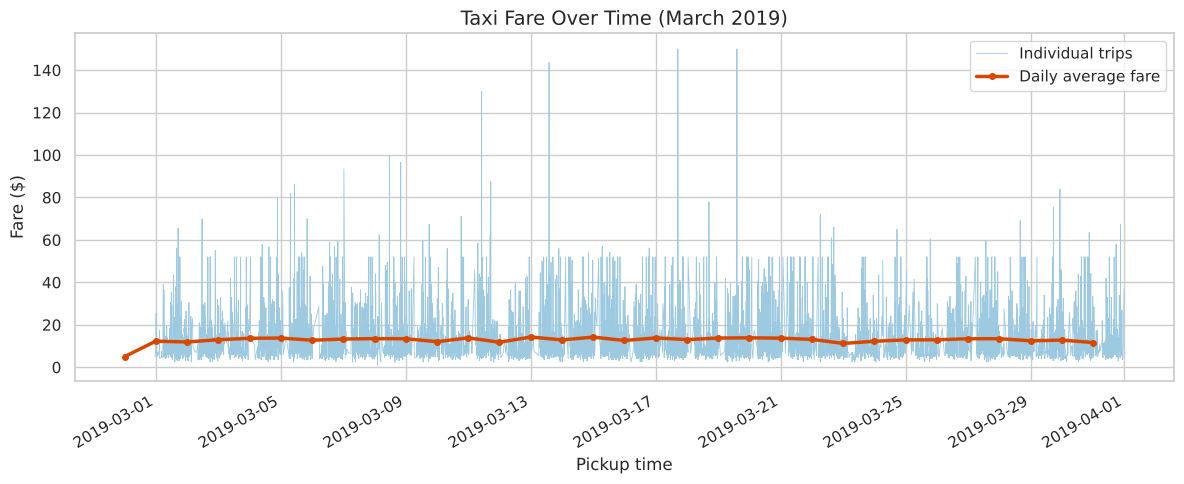

In [5]:
df_clean["pickup"] = pd.to_datetime(df_clean["pickup"])
ts = df_clean.sort_values("pickup")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ts["pickup"], ts["fare"], color="#9ecae1", linewidth=0.6, label="Individual trips")
daily = ts.set_index("pickup")["fare"].resample("D").mean()
ax.plot(daily.index, daily.values, color="#d94801", linewidth=2.5, marker="o", markersize=4,
        label="Daily average fare")
ax.set_title("Taxi Fare Over Time (March 2019)", fontsize=14)
ax.set_xlabel("Pickup time")
ax.set_ylabel("Fare ($)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 3.2 Bar chart: total fare by pickup borough

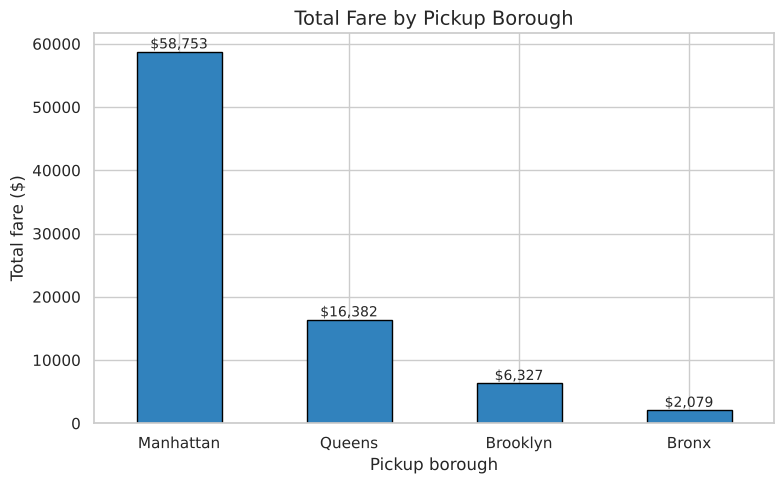

pickup_borough
Manhattan    58753.42
Queens       16382.06
Brooklyn      6327.48
Bronx         2078.91
Name: fare, dtype: float64

In [6]:
borough_fare = df_clean.groupby("pickup_borough")["fare"].sum().sort_values(ascending=False)

ax = borough_fare.plot(kind="bar", figsize=(8, 5), color="#3182bd", edgecolor="black")
ax.set_title("Total Fare by Pickup Borough", fontsize=14)
ax.set_xlabel("Pickup borough")
ax.set_ylabel("Total fare ($)")
plt.xticks(rotation=0)
for i, v in enumerate(borough_fare):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()
borough_fare

### 3.3 Pie chart: trips by payment method

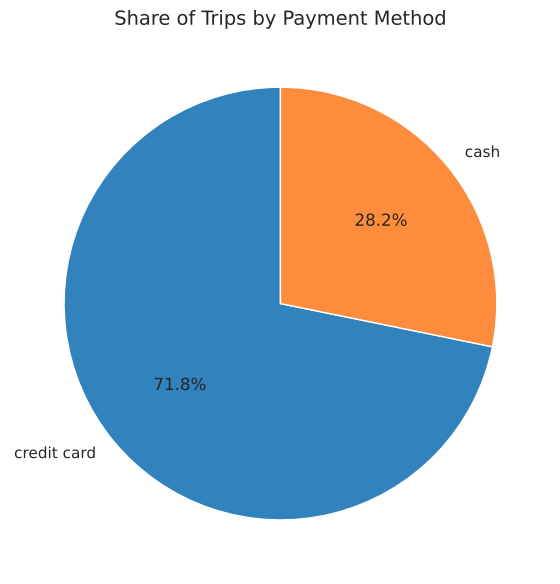

payment
credit card    4600
cash           1807
Name: count, dtype: int64

In [7]:
pay_counts = df_clean["payment"].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(pay_counts, labels=pay_counts.index, autopct="%1.1f%%", startangle=90,
       colors=["#3182bd", "#fd8d3c"], wedgeprops={"edgecolor": "white"})
ax.set_title("Share of Trips by Payment Method", fontsize=14)
plt.tight_layout()
plt.show()
pay_counts

### 3.4 Histogram: distribution of trip distance

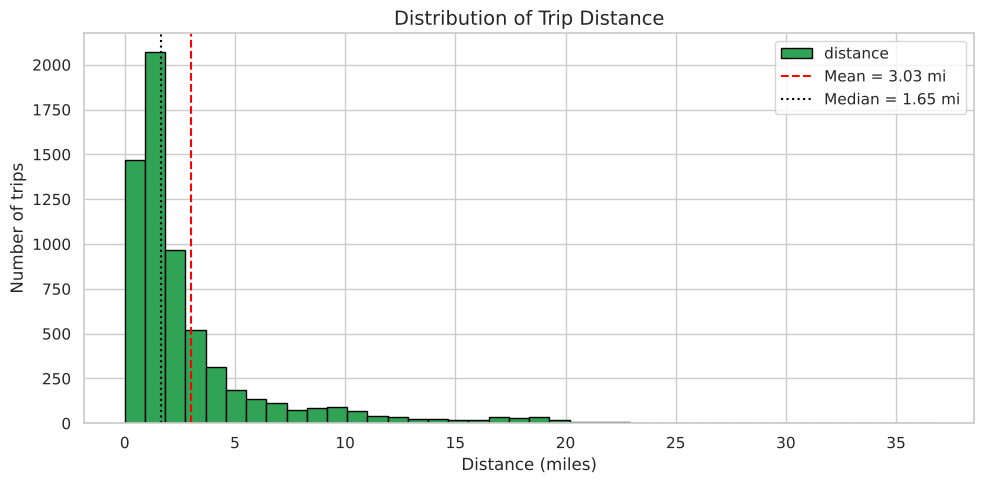

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
df_clean["distance"].plot(kind="hist", bins=40, ax=ax, color="#31a354", edgecolor="black")
ax.axvline(df_clean["distance"].mean(), color="red", linestyle="--",
           label=f"Mean = {df_clean['distance'].mean():.2f} mi")
ax.axvline(df_clean["distance"].median(), color="black", linestyle=":",
           label=f"Median = {df_clean['distance'].median():.2f} mi")
ax.set_title("Distribution of Trip Distance", fontsize=14)
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Number of trips")
ax.legend()
plt.tight_layout()
plt.show()

### 3.5 Box plot: tip amount by pickup borough

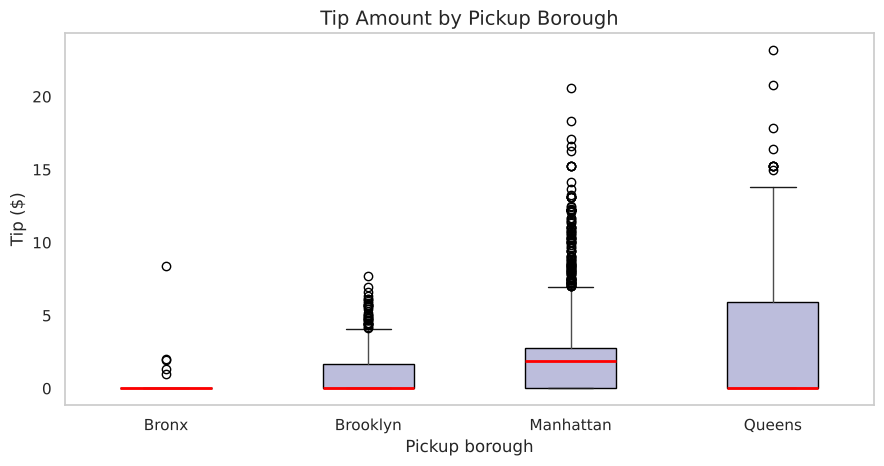

,count,mean,std,min,25%,50%,75%,max
pickup_borough,,,,,,,,
Bronx,99.0,0.15,0.90,0.0,0.0,0.00,0.00,8.39
Brooklyn,383.0,0.97,1.67,0.0,0.0,0.00,1.65,7.70
Manhattan,5268.0,1.94,2.02,0.0,0.0,1.86,2.80,20.56
Queens,657.0,3.04,4.35,0.0,0.0,0.00,5.95,23.19


In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
df_clean.boxplot(column="tip", by="pickup_borough", ax=ax, grid=False,
                 patch_artist=True, boxprops=dict(facecolor="#bcbddc"),
                 medianprops=dict(color="red", linewidth=2))
ax.set_title("Tip Amount by Pickup Borough", fontsize=14)
fig.suptitle("")  # remove pandas' automatic super-title
ax.set_xlabel("Pickup borough")
ax.set_ylabel("Tip ($)")
plt.tight_layout()
plt.show()
df_clean.groupby("pickup_borough")["tip"].describe().round(2)

## 4. Visualizations using Seaborn

### 4.1 Count plot: trips per pickup borough

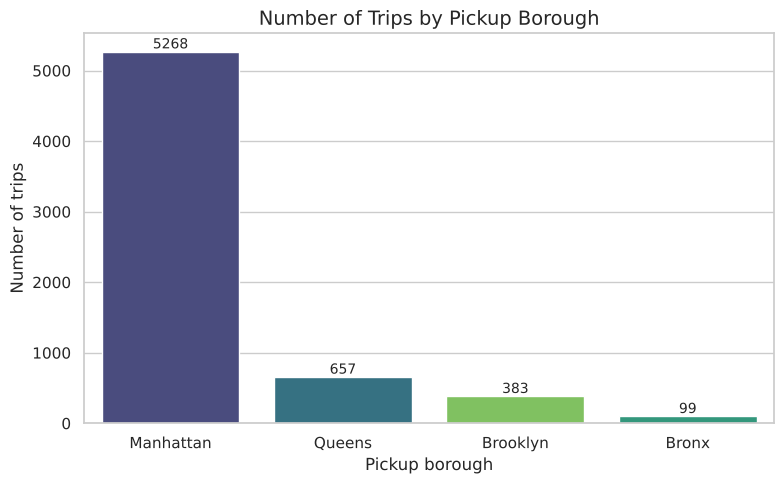

In [10]:
order = df_clean["pickup_borough"].value_counts().index
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df_clean, x="pickup_borough", order=order, hue="pickup_borough",
              palette="viridis", legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Number of Trips by Pickup Borough", fontsize=14)
ax.set_xlabel("Pickup borough")
ax.set_ylabel("Number of trips")
plt.tight_layout()
plt.show()

### 4.2 Scatter plot: distance vs fare, coloured by pickup borough

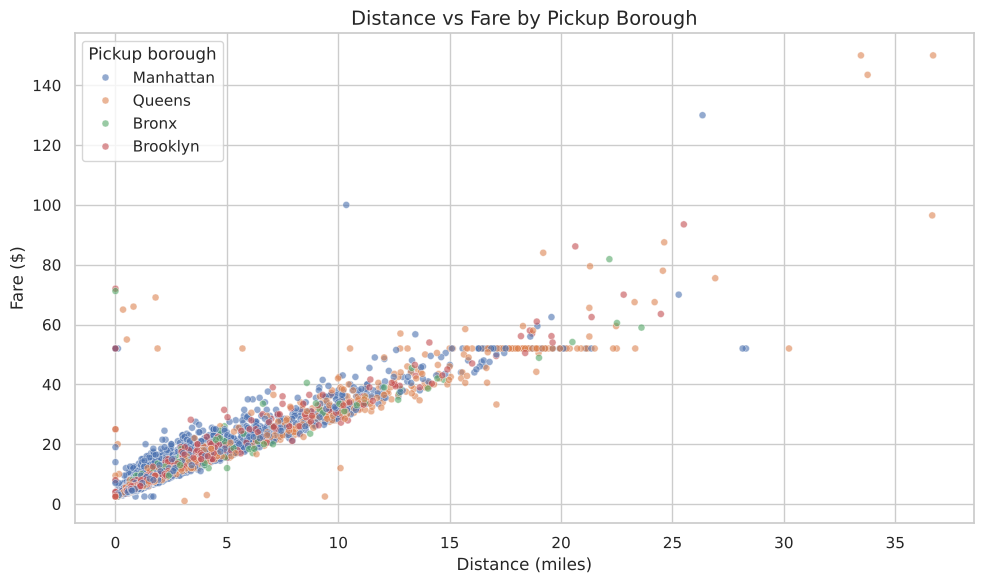

Correlation (distance, fare): 0.939


In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_clean, x="distance", y="fare", hue="pickup_borough",
                alpha=0.6, s=25, ax=ax)
ax.set_title("Distance vs Fare by Pickup Borough", fontsize=14)
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Fare ($)")
ax.legend(title="Pickup borough")
plt.tight_layout()
plt.show()
print("Correlation (distance, fare):", round(df_clean["distance"].corr(df_clean["fare"]), 3))

### 4.3 Heatmap: correlation of numeric variables

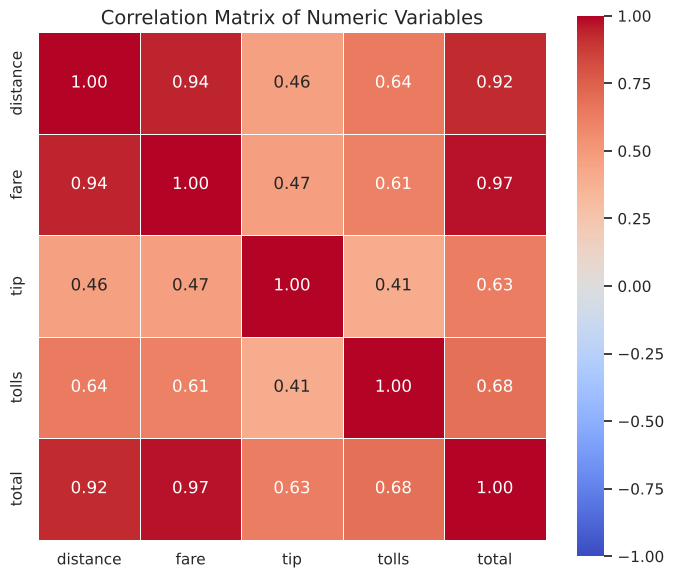

In [12]:
num_cols = ["distance", "fare", "tip", "tolls", "total"]
corr = df_clean[num_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, square=True, ax=ax)
ax.set_title("Correlation Matrix of Numeric Variables", fontsize=14)
plt.tight_layout()
plt.show()

### 4.4 Pair plot: distance, fare, tip, total coloured by pickup zone

The data has 190+ pickup zones, which would make an unreadable legend and tiny colour groups. To keep the plot interpretable I colour the **5 busiest pickup zones** and leave the rest out of this one figure only.

Using 1057 trips from the top 5 zones: ['Midtown Center', 'Upper East Side South', 'Penn Station/Madison Sq West', 'Clinton East', 'Midtown East']


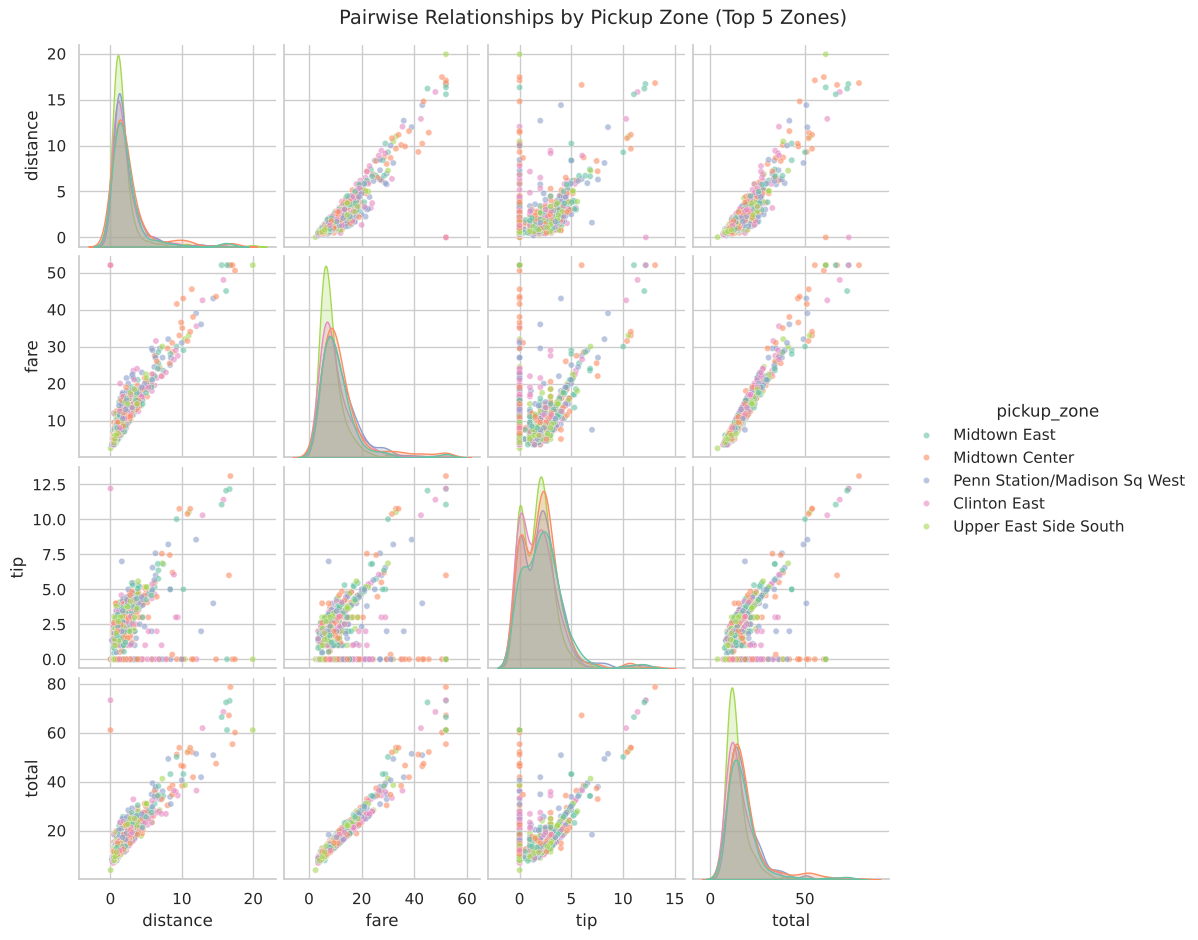

In [13]:
top_zones = df_clean["pickup_zone"].value_counts().head(5).index
pair_df = df_clean[df_clean["pickup_zone"].isin(top_zones)]
print(f"Using {len(pair_df)} trips from the top 5 zones: {list(top_zones)}")

g = sns.pairplot(pair_df, vars=["distance", "fare", "tip", "total"],
                 hue="pickup_zone", palette="Set2", diag_kind="kde",
                 plot_kws={"alpha": 0.6, "s": 20}, height=2.3)
g.figure.suptitle("Pairwise Relationships by Pickup Zone (Top 5 Zones)", y=1.02, fontsize=14)
plt.show()

### 4.5 Violin plot: fare by payment method

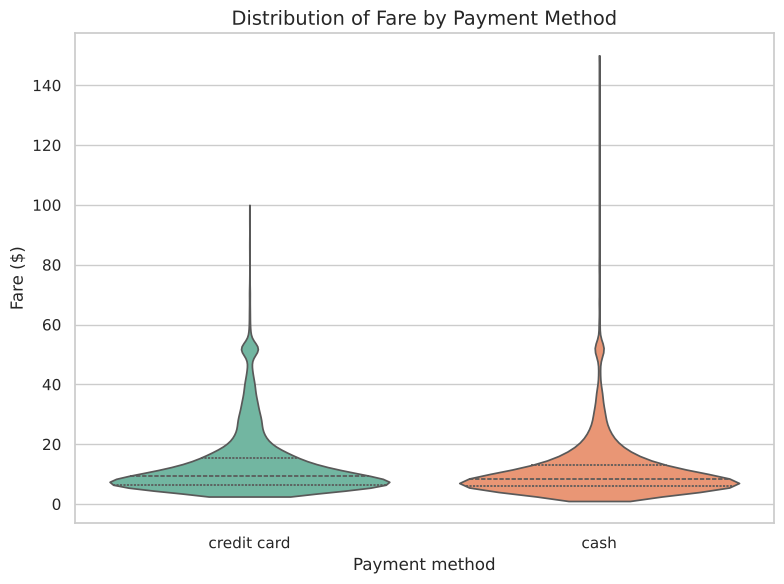

,count,mean,std,min,25%,50%,75%,max
payment,,,,,,,,
cash,1807.0,11.61,11.25,1.0,6.0,8.5,13.0,150.0
credit card,4600.0,13.60,11.36,2.5,6.5,9.5,15.5,100.0


In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.violinplot(data=df_clean, x="payment", y="fare", hue="payment", palette="Set2",
               inner="quartile", cut=0, legend=False, ax=ax)
ax.set_title("Distribution of Fare by Payment Method", fontsize=14)
ax.set_xlabel("Payment method")
ax.set_ylabel("Fare ($)")
plt.tight_layout()
plt.show()
df_clean.groupby("payment")["fare"].describe().round(2)

## 5. Key takeaways

**Data cleaning**
- 6,433 trips loaded. Missing values were only in categorical columns: `payment` (44), `dropoff_zone`/`dropoff_borough` (45 each), `pickup_zone`/`pickup_borough` (26 each).
- Filled `payment` and the dropoff columns with the mode; dropped the 26 rows with no pickup location. Final dataset: **6,407 trips, 0 missing values**.

**Findings**
1. **Manhattan dominates volume.** 5,268 of 6,407 trips (82%) start in Manhattan, and they bring in about 70% of total fare. Queens has only 10% of trips but 20% of fare.
2. **Short trips vs long trips.** Manhattan trips have the lowest average fare (about $11) and distance (2.4 mi). Queens has the highest (about $25, 7.5 mi), which fits long runs out of the borough.
3. **Distance drives fare.** Distance and fare correlate at 0.94, and total is almost entirely fare (0.97). Trip distance is right-skewed: median 1.65 mi vs mean 3.03 mi.
4. **Payment mix.** About 72% of trips are paid by credit card and 28% by cash. Fare distributions look similar for both, with a small bump near $50 for each (likely flat-rate trips).
5. **Tips need care.** Every cash trip has a tip of $0, so tips appear to be recorded only for card payments. The low tip medians in the Bronx, Brooklyn and Queens partly reflect payment mix, not just rider generosity. Tip correlates only moderately with fare and distance (about 0.46 to 0.47).
6. **Time pattern.** Daily average fare is steady (roughly $11 to $14) all month, a little lower on weekends. There is no strong trend.
7. **Pickup zone.** In the pair plot the five busiest zones overlap heavily, so zone alone does not separate trips by distance, fare, tip or total.